# Chapter 6: knn

In [1]:
%reset
low_memory=False

import pandas as pd
import matplotlib.pyplot as plt
import imblearn
import seaborn as sns
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from imblearn.metrics import specificity_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score


from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

## 6.1 Introduction & Motivation

Now that we've seen two classification models, it's time to add a third one: knn or *k nearest neighbours*. This model essentials works based on one single question: **When looking at the *k* datapoints closest to me, which label occurs the most?**

This model is easy to understand but can be tricky to tune, especially when it comes to finding the best value for k. In this excercise you will put the model to the test, compare it to the ones you already know and explore new ways to get the best evaluation!

## 6.2 Problem Setting

After a war, often dangerous equipement gets left behind scattered around a field. Over time these can become buried in the earth and lost to time. However, at some point later in time civilians sometimes find still live explosives leading to dangerous situations. Over here in flanders for example, to this day farmers still find live mines from WW 1 when plowing their fields.

To combat this and take out as many of them as possible, a government can take some sonar scans of the ground. The dataset that we are going to explore today contains a series of object, each scanned 60 times with a sonar from different angles. We are trying to predict whether a scanned object is an actual mine 'M' or a rock shaped like a mine 'R'. These values are stored in the 'Material' column.

## 6.3 Model

First, let's have a look at the data.

In [2]:
df = pd.read_csv("Sonar.csv")
df.head()

,Sonar1,Sonar2,Sonar3,Sonar4,Sonar5,Sonar6,Sonar7,Sonar8,Sonar9,Sonar10,...,Sonar52,Sonar53,Sonar54,Sonar55,Sonar56,Sonar57,Sonar58,Sonar59,Sonar60,Material
0,0.0664,0.0575,0.0842,0.0372,0.0458,0.0771,0.0771,0.1130,0.2353,0.1838,...,0.0141,0.0190,0.0043,0.0036,0.0026,0.0024,0.0162,0.0109,0.0079,R
1,0.0094,0.0333,0.0306,0.0376,0.1296,0.1795,0.1909,0.1692,0.1870,0.1725,...,0.0153,0.0112,0.0241,0.0164,0.0055,0.0078,0.0055,0.0091,0.0067,M
2,0.0201,0.0178,0.0274,0.0232,0.0724,0.0833,0.1232,0.1298,0.2085,0.2720,...,0.0131,0.0049,0.0104,0.0102,0.0092,0.0083,0.0020,0.0048,0.0036,M
3,0.0526,0.0563,0.1219,0.1206,0.0246,0.1022,0.0539,0.0439,0.2291,0.1632,...,0.0339,0.0149,0.0335,0.0376,0.0174,0.0132,0.0103,0.0364,0.0208,M
4,0.0261,0.0266,0.0223,0.0749,0.1364,0.1513,0.1316,0.1654,0.1864,0.2013,...,0.0222,0.0175,0.0127,0.0022,0.0124,0.0054,0.0021,0.0028,0.0023,M


##### Question 1: Try and plot a heatmap to further explore the data. Do you run into any errors? Why is this? How can you solve this using a method we've already seen?

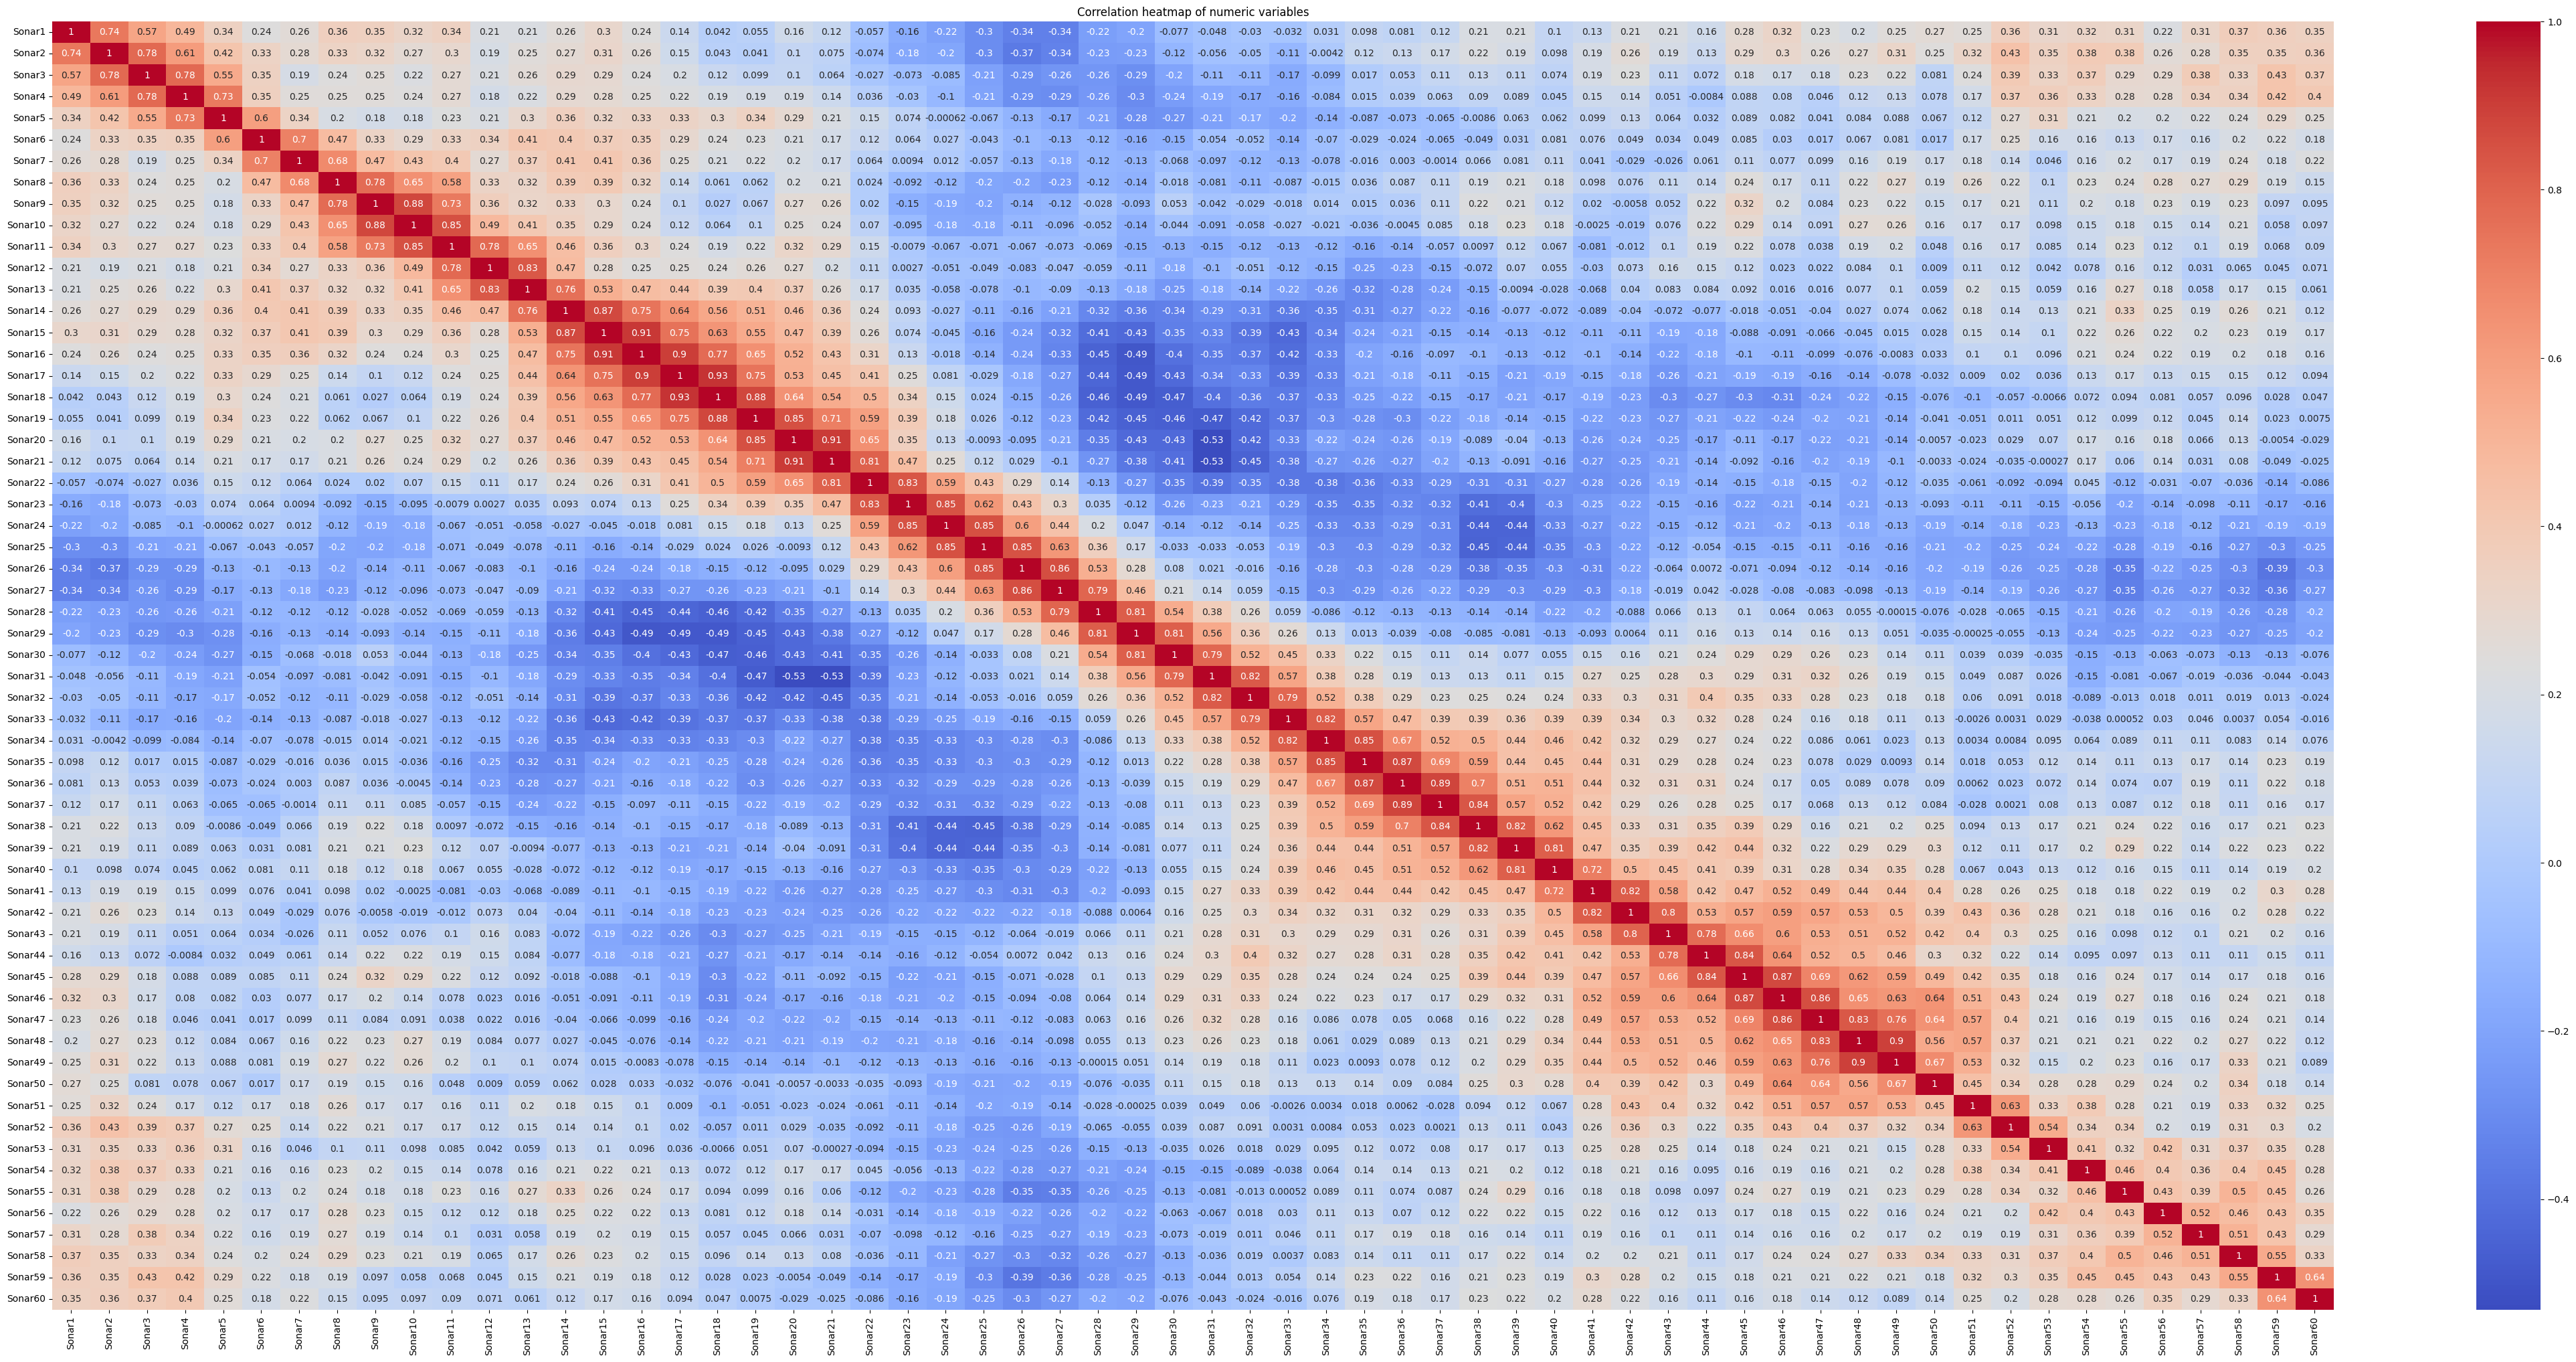

The error happens because Material is categorical/text instead of numeric.
Solution: remove the non-numeric column or encode it first.


In [3]:
numeric_df = df.select_dtypes(include='number')
plt.figure(figsize=(55, 25))
sns.heatmap(numeric_df.corr(), cmap='coolwarm', annot=True)
plt.title('Correlation heatmap of numeric variables')
plt.show()

print('The error happens because Material is categorical/text instead of numeric.')
print('Solution: remove the non-numeric column or encode it first.')


##### Question 2: Just as always, explore the data by looking at the heatmap. Which variables would you expect to have the highest impact on Material and which ones would you expect to have the lowest impact? Why?

**Antwoord:** Variabelen met de sterkste positieve of negatieve kleur t.o.v. andere variabelen lijken het meeste structuur te bevatten en hebben dus vermoedelijk de grootste impact op `Material`. Variabelen die bijna geen correlaties tonen of heel neutrale kleuren hebben, verwacht ik minder belangrijk. Op basis van alleen de heatmap blijft dit wel een eerste inschatting: de echte impact bevestig je pas met modelprestaties of feature importance.

##### Question 3: Build and train your model. Make sure to keep some data on the side for testing and to exclude your final column in your training data!

In [4]:
X = df.drop(columns=['Material'])
y = df['Material']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

knn = KNeighborsClassifier()
knn.fit(X_train, y_train)

print('Train shape:', X_train.shape)
print('Test shape:', X_test.shape)


Train shape: (166, 60)
Test shape: (42, 60)


##### Question 4: Predict the materials of your testing data. How many rocks are there? And how many mines?

In [5]:
y_pred = knn.predict(X_test)
print(y_pred,'\n\n---------\n---------\n')

pred_counts = pd.Series(y_pred).value_counts()
print('Predicted rocks (R):', pred_counts.get('R', 0))
print('Predicted mines (M):', pred_counts.get('M', 0))
pred_counts


['R' 'R' 'R' 'M' 'M' 'M' 'M' 'R' 'M' 'M' 'M' 'M' 'R' 'R' 'M' 'R' 'R' 'M'
 'R' 'M' 'R' 'M' 'M' 'R' 'M' 'R' 'M' 'M' 'M' 'M' 'R' 'M' 'R' 'R' 'R' 'M'
 'M' 'M' 'M' 'M' 'R' 'R'] 

---------
---------

Predicted rocks (R): 18
Predicted mines (M): 24


M    24
R    18
Name: count, dtype: int64

## 6.4 Model Evaluation

Of course our predictions don't mean anything without knowing how good they are. Let's explore this.

##### Question 5: Is your model any good? Elaborate by calculation accuracy and precision.

In [6]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label='M')

print('Accuracy:', accuracy)
print('Precision:', precision)

if accuracy >= 0.8:
    print('The model performs reasonably well on this test set.')
else:
    print('The model is not very strong on this test set and may need tuning.')


Accuracy: 0.7619047619047619
Precision: 0.75
The model is not very strong on this test set and may need tuning.


##### Question 6: Can you visually confirm your previous findings by plotting a confusion matrix?

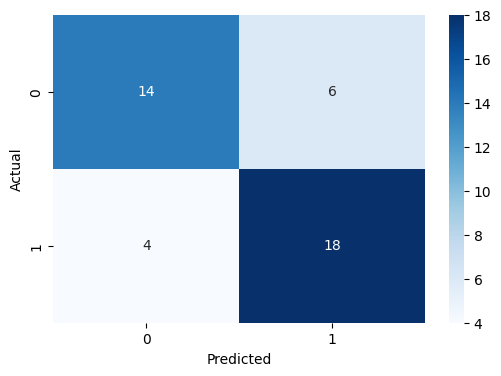

In [7]:
cm = metrics.confusion_matrix(y_test, y_pred, labels=['R', 'M'])
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


##### Question 7: Calculate the other methods we've seen. Are they any good? Elaborate. In the current dataset, would you prefer a high recall or specificity? Why?
*Remember that we are working with a binary solution, not a multiclass solution!*

In [8]:
recall = recall_score(y_test, y_pred, pos_label='M')
specificity = specificity_score(y_test, y_pred, pos_label='M')
f1 = f1_score(y_test, y_pred, pos_label='M')

print('Recall:', recall)
print('Specificity:', specificity)
print('F1-score:', f1)
print('\nClassification report:')
print(classification_report(y_test, y_pred))

print('\nFor this dataset, high recall for mines is very important.')
print('Missing a real mine is more dangerous than wrongly flagging a rock.')


Recall: 0.8181818181818182
Specificity: 0.7
F1-score: 0.782608695652174

Classification report:
              precision    recall  f1-score   support

           M       0.75      0.82      0.78        22
           R       0.78      0.70      0.74        20

    accuracy                           0.76        42
   macro avg       0.76      0.76      0.76        42
weighted avg       0.76      0.76      0.76        42


For this dataset, high recall for mines is very important.
Missing a real mine is more dangerous than wrongly flagging a rock.


## 6.5 Questions

##### Question 1: See section 6.3

##### Question 2: See section 6.3

##### Question 3: See section 6.3

##### Question 4: See section 6.3

##### Question 5: See section 6.4

##### Question 6: See section 6.4

##### Question 7: See section 6.4

##### Question 8: By default, python will use 5 as the amount of nearest neighbours. Try and find the best value by plotting a series of possible values.

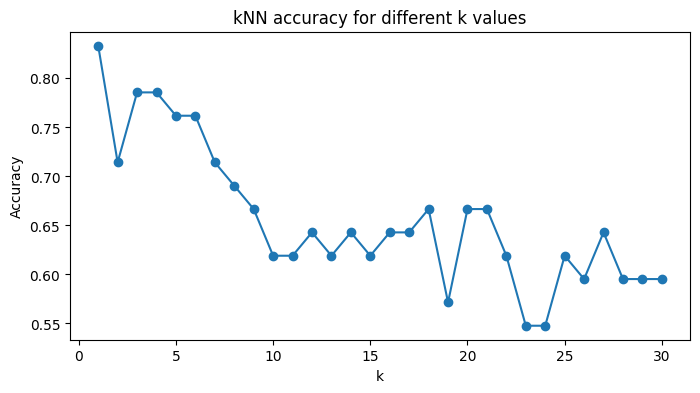

Best k based on accuracy: 1
Best accuracy: 0.8333333333333334


In [9]:
k_values = list(range(1, 31))
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    accuracies.append(accuracy_score(y_test, preds))

plt.figure(figsize=(8, 4))
plt.plot(k_values, accuracies, marker='o')
plt.xlabel('k')
plt.ylabel('Accuracy')
plt.title('kNN accuracy for different k values')
plt.show()

best_k_accuracy = k_values[accuracies.index(max(accuracies))]
print('Best k based on accuracy:', best_k_accuracy)
print('Best accuracy:', max(accuracies))


##### Question 9: Do the same for the metric you want to maximize. Does your preferred value for n change? Which value would be 'best' in the end for this data?

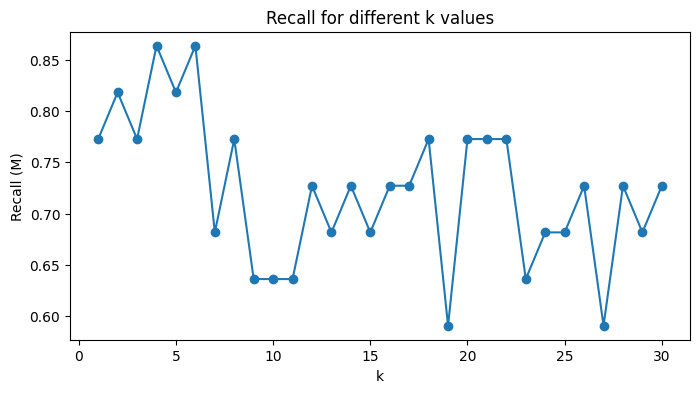

Best k based on recall: 4
Best recall: 0.8636363636363636
Final choice depends on the goal: for safety, recall is often the most important.


In [10]:
recalls = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    recalls.append(recall_score(y_test, preds, pos_label='M'))

plt.figure(figsize=(8, 4))
plt.plot(k_values, recalls, marker='o')
plt.xlabel('k')
plt.ylabel('Recall (M)')
plt.title('Recall for different k values')
plt.show()

best_k_recall = k_values[recalls.index(max(recalls))]
print('Best k based on recall:', best_k_recall)
print('Best recall:', max(recalls))
print('Final choice depends on the goal: for safety, recall is often the most important.')


##### Question 10: Train a logistic regression, decision trees and random forest model on this data. Try and find the best models you can using the methods we've explored in earlier lessons. Which model do you prefer?

In [11]:
log_model = LogisticRegression(max_iter=1000)
tree_model = DecisionTreeClassifier(max_depth=5, random_state=42)
rf_model = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42)

models = {
    'kNN': KNeighborsClassifier(n_neighbors=best_k_recall),
    'Logistic Regression': log_model,
    'Decision Tree': tree_model,
    'Random Forest': rf_model
}

comparison = []
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    comparison.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision_M': precision_score(y_test, preds, pos_label='M'),
        'Recall_M': recall_score(y_test, preds, pos_label='M'),
        'F1_M': f1_score(y_test, preds, pos_label='M')
    })

comparison_df = pd.DataFrame(comparison).sort_values(by='Recall_M', ascending=False)
comparison_df

,Model,Accuracy,Precision_M,Recall_M,F1_M
3,Random Forest,0.904762,0.875000,0.954545,0.913043
0,kNN,0.785714,0.760000,0.863636,0.808511
2,Decision Tree,0.690476,0.695652,0.727273,0.711111
1,Logistic Regression,0.714286,0.777778,0.636364,0.700000


**Antwoord:** Het voorkeursmodel hangt af van de prioriteit. Als veiligheid primeert, kies ik het model met de hoogste recall voor `M`, omdat een gemiste mijn het gevaarlijkste scenario is. Als twee modellen gelijkaardig scoren, heeft het eenvoudigere en stabielere model meestal de voorkeur.

##### Question 11: It might just so happen that the test set we are using does not properly represent the whole dataset we have and thus might unfairly favor one model. A way to combat this is called cross validation. Do some research and implement this method using a 10-fold. Does the outcome you found above change?

In [12]:
cv_results = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=10, scoring='recall_macro')
    cv_results.append({
        'Model': name,
        'CV mean recall_macro': scores.mean(),
        'CV std': scores.std()
    })

cv_df = pd.DataFrame(cv_results).sort_values(by='CV mean recall_macro', ascending=False)
cv_df

,Model,CV mean recall_macro,CV std
3,Random Forest,0.810859,0.098449
0,kNN,0.774545,0.063576
1,Logistic Regression,0.757525,0.086413
2,Decision Tree,0.724672,0.122040


**Antwoord:** Met 10-fold cross validation krijg je een betrouwbaarder beeld dan met één enkele test split. Het kan dus gebeuren dat de rangorde van de modellen licht verandert. Het model dat gemiddeld het sterkst scoort over de 10 folds is uiteindelijk de veiligste keuze.